# Downloading MICrONS

The code below will download parts of the MICrONS database that we are interested in. Specifically, we're looking for:
- Neurons with calcium imaging data
- Neuron pairs that have proofread synapses

To do this, you need to get an API token for CAVE. Here's how you go about doing that:
1. Go to https://global.daf-apis.com/auth/api/v1/create_token to create a new token
2. Log in with your Google credentials and copy the token shown afterward
3. Paste your token into the `.env` file (you create yourself) under `TOKEN=`

In [89]:
%pip install -U caveclient pandas numpy python-dotenv

  Using cached pandas-3.0.6-cp313-cp313-macosx_11_0_arm64.whl.metadata (79 kB)

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [90]:
import os
from dotenv import load_dotenv
from caveclient import CAVEclient

load_dotenv()

client = CAVEclient(
  datastack_name="minnie65_public",
  version=1926,
  auth_token=os.getenv("TOKEN"),
)

## 1. Check which neurons are proofread
Some neurons are proofread, and to different levels. Here is the procedure:
1. Filter for valid records (`valid=True`)
2. Filter for either `status_dendrite | status_axon=True` and `strategy_axon=axon_fully_extended | strategy_dendrite=dendrite_extended`
3. Confirm exactly one record per neuron (`pt_root_id`) and construct list

In [91]:
proofread_df = client.materialize.query_table(
  "proofreading_status_and_strategy",
  desired_resolution=[1, 1, 1],
  split_positions=True,
)
print(proofread_df.columns.to_list())
display(proofread_df.head())

['id', 'created', 'superceded_id', 'valid', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'valid_id', 'status_dendrite', 'status_axon', 'strategy_dendrite', 'strategy_axon', 'pt_supervoxel_id', 'pt_root_id']


,id,created,superceded_id,valid,pt_position_x,pt_position_y,pt_position_z,valid_id,status_dendrite,status_axon,strategy_dendrite,strategy_axon,pt_supervoxel_id,pt_root_id
0,4584,2025-11-17 21:56:20.328504+00:00,<NA>,True,1185856,444800,670800,864691135686494647,True,True,dendrite_extended,axon_fully_extended,105489482232831453,864691135686494647
1,5952,2026-09-23 00:07:17.663435+00:00,<NA>,True,716644,859320,1086120,864691135210716537,False,True,none,axon_fully_extended,89388991278804869,864691135210716537
2,5953,2026-09-23 00:53:52.311874+00:00,<NA>,True,821632,418368,883000,864691135939998724,True,True,dendrite_extended,axon_fully_extended,93033321898015624,864691135939998724
3,9,2024-06-03 19:45:52.508002+00:00,<NA>,True,1329476,475260,700720,864691136812081779,True,True,dendrite_extended,axon_interareal,110486693995521385,864691136812081779
4,14,2024-06-03 19:45:52.512832+00:00,<NA>,True,692736,869888,877160,864691136195284556,True,True,dendrite_extended,axon_fully_extended,88615277952475942,864691136195284556


In [169]:
n_records = proofread_df.shape[0]
proofread_valid_df = proofread_df[
  (proofread_df["valid"] == True) &
  (
    (proofread_df["status_axon"] == True) |
    (proofread_df["status_dendrite"] == True)
  ) &
  (
    (proofread_df["strategy_axon"] == "axon_fully_extended") |
    (proofread_df["strategy_dendrite"] == "dendrite_extended")
  ) &
  (proofread_df["valid_id"] == proofread_df["pt_root_id"])
].copy()
n_valid_records = proofread_valid_df.shape[0]

proofread_pre_ids = set(proofread_valid_df[proofread_df["strategy_axon"] == "axon_fully_extended"].copy()["pt_root_id"].astype("int64"))
proofread_post_ids = set(proofread_valid_df[proofread_df["strategy_dendrite"] == "dendrite_extended"].copy()["pt_root_id"].astype("int64"))
proofread_ids = proofread_pre_ids.union(proofread_post_ids)

print(f"n_records=        {n_records}")
print(f"n_valid_records=  {n_valid_records}")
print(f"n_pr_pre=         {len(proofread_pre_ids)}")
print(f"n_pr_post=        {len(proofread_post_ids)}")

n_records=        2345
n_valid_records=  2075
n_pr_pre=         802
n_pr_post=        2021


/var/folders/kt/6dtp82192078vqz9pmrb32lm0000gn/T/ipykernel_59964/3261210969.py:16: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  proofread_pre_ids = set(proofread_valid_df[proofread_df["strategy_axon"] == "axon_fully_extended"].copy()["pt_root_id"].astype("int64"))
/var/folders/kt/6dtp82192078vqz9pmrb32lm0000gn/T/ipykernel_59964/3261210969.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  proofread_post_ids = set(proofread_valid_df[proofread_df["strategy_dendrite"] == "dendrite_extended"].copy()["pt_root_id"].astype("int64"))


## 2. Find all calcium-imaged and EM-imaged neurons

Basic query and filtering. Not hard.

In [123]:
coreg_df = client.materialize.query_table(
  "coregistration_manual_v4",
  desired_resolution=[1, 1, 1],
  split_positions=True,
)
print(coreg_df.columns.to_list())
display(coreg_df.head())

['id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id', 'pt_root_id', 'id', 'created', 'valid', 'target_id', 'session', 'scan_idx', 'unit_id', 'field', 'residual', 'score']


,id_ref,created_ref,valid_ref,volume,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,...,id,created,valid,target_id,session,scan_idx,unit_id,field,residual,score
0,492564,2020-09-28 22:41:00.815893+00:00,True,312.260376,1126848,697600,711480,<NA>,<NA>,<NA>,...,4229,2024-05-21 18:38:24.663935+00:00,True,492564,5,7,7276,6,4.9403,6.3722
1,335649,2020-09-28 22:41:20.303372+00:00,True,295.861115,843136,728128,906920,<NA>,<NA>,<NA>,...,5491,2024-05-21 18:38:25.372047+00:00,True,335649,6,2,6883,6,7.41244,2.60806
2,224395,2020-09-28 22:41:32.572651+00:00,True,329.448334,599360,532608,903680,<NA>,<NA>,<NA>,...,10490,2024-05-21 18:42:39.170710+00:00,True,224395,7,3,2398,2,7.02217,-1.39408
3,224395,2020-09-28 22:41:32.572651+00:00,True,329.448334,599360,532608,903680,<NA>,<NA>,<NA>,...,19021,2024-05-21 18:42:43.833831+00:00,True,224395,9,6,4843,4,9.55213,5.02637
4,332833,2020-09-28 22:44:41.864456+00:00,True,274.418732,837312,697216,800160,<NA>,<NA>,<NA>,...,9672,2024-05-21 18:42:38.724265+00:00,True,332833,6,7,6413,6,5.27806,7.80804


In [124]:
coreg_df = coreg_df[coreg_df["valid"] == True].copy()
coreg_df = coreg_df.drop_duplicates(subset=["pt_root_id", "session", "scan_idx", "unit_id"])

coreg_ids = set(coreg_df["pt_root_id"].astype("int64"))

print(f"n_coreg_ids=  {len(coreg_ids)}")

n_coreg_ids=  15434


In [195]:
FILTER_PROOFREAD = 0
FILTER_NONE = 1
FILTER_FIRST = 2

filter_type = FILTER_FIRST

if filter_type == FILTER_PROOFREAD:
  valid_coreg_df = coreg_df[coreg_df["pt_root_id"].isin(proofread_ids)].copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_pre_ids = valid_coreg_ids.intersection(proofread_pre_ids)
  valid_coreg_post_ids = valid_coreg_ids.intersection(proofread_post_ids)
elif filter_type == FILTER_NONE:
  valid_coreg_df = coreg_df.copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_pre_ids = valid_coreg_ids
  valid_coreg_post_ids = valid_coreg_ids
elif filter_type == FILTER_FIRST:
  valid_coreg_df = coreg_df.copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_ids = set(list(valid_coreg_ids)[:3000])
  valid_coreg_df = valid_coreg_df[valid_coreg_df["pt_root_id"].isin(valid_coreg_ids)]
  valid_coreg_pre_ids = valid_coreg_ids
  valid_coreg_post_ids = valid_coreg_ids
else:
  exit(1)

print(f"n_valid_coreg_ids=     {len(valid_coreg_ids)}")
print(f"valid_coreg_pre_ids=   {len(valid_coreg_post_ids)}")
print(f"valid_coreg_post_ids=  {len(valid_coreg_post_ids)}")

n_valid_coreg_ids=     3000
valid_coreg_pre_ids=   3000
valid_coreg_post_ids=  3000


## 3. Load all synapses that we care about

Again, basic querying. No filtering this time.

In [153]:
from pathlib import Path
import pandas as pd

pre_ids = sorted(map(int, valid_coreg_pre_ids))
post_ids = sorted(map(int, valid_coreg_post_ids))

cache_dir = Path("cache/synapse_batches")
cache_dir.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 500
batch_files = []

pre_batches = [
  pre_ids[i:i + BATCH_SIZE]
  for i in range(0, len(pre_ids), BATCH_SIZE)
]
post_batches = [
  post_ids[i:i + BATCH_SIZE]
  for i in range(0, len(post_ids), BATCH_SIZE)
]

for i, pre_batch in enumerate(pre_batches):
  for j, post_batch in enumerate(post_batches):
    batch_path = cache_dir / f"pre_{i}_post_{j}.parquet"
    batch_files.append(batch_path)

    if batch_path.exists():
      print(f"Cached batch {i}, {j}")
      continue

    print(f"Querying batch {i + 1}/{len(pre_batches)}, {j + 1}/{len(post_batches)}")

    df = client.materialize.query_table(
      "synapses_pni_2",
      filter_in_dict={
          "pre_pt_root_id": pre_batch,
          "post_pt_root_id": post_batch,
      },
      select_columns=[
          "pre_pt_root_id",
          "post_pt_root_id",
      ],
      materialization_version=1926,
    )
    df.to_parquet(batch_path, index=False)

synapses_df = pd.concat(
  [pd.read_parquet(path) for path in batch_files],
  ignore_index=True,
).drop_duplicates()

print(synapses_df.columns.to_list())
print(synapses_df.head())

Querying batch 1/6, 1/6
Querying batch 1/6, 2/6
Querying batch 1/6, 3/6
Querying batch 1/6, 4/6
Querying batch 1/6, 5/6
Querying batch 1/6, 6/6
Querying batch 2/6, 1/6
Querying batch 2/6, 2/6
Querying batch 2/6, 3/6
Querying batch 2/6, 4/6
Querying batch 2/6, 5/6
Querying batch 2/6, 6/6
Querying batch 3/6, 1/6
Querying batch 3/6, 2/6
Querying batch 3/6, 3/6
Querying batch 3/6, 4/6
Querying batch 3/6, 5/6
Querying batch 3/6, 6/6
Querying batch 4/6, 1/6
Querying batch 4/6, 2/6
Querying batch 4/6, 3/6
Querying batch 4/6, 4/6
Querying batch 4/6, 5/6
Querying batch 4/6, 6/6
Querying batch 5/6, 1/6
Querying batch 5/6, 2/6
Querying batch 5/6, 3/6
Querying batch 5/6, 4/6
Querying batch 5/6, 5/6
Querying batch 5/6, 6/6
Querying batch 6/6, 1/6
Querying batch 6/6, 2/6
Querying batch 6/6, 3/6
Querying batch 6/6, 4/6
Querying batch 6/6, 5/6
Querying batch 6/6, 6/6
['pre_pt_supervoxel_id', 'pre_pt_root_id', 'post_pt_supervoxel_id', 'post_pt_root_id']
   pre_pt_supervoxel_id      pre_pt_root_id  post

In [160]:
synapses_df = synapses_df[
  synapses_df["pre_pt_root_id"].isin(valid_coreg_pre_ids) &
  synapses_df["post_pt_root_id"].isin(valid_coreg_post_ids)
]
synapses_df = synapses_df[synapses_df["pre_pt_root_id"] != synapses_df["post_pt_root_id"]]

# just makin' sure i didn't screw up
assert len(valid_coreg_pre_ids.union(set(synapses_df["pre_pt_root_id"].astype("int64")))) == len(valid_coreg_pre_ids)
assert len(valid_coreg_post_ids.union(set(synapses_df["post_pt_root_id"].astype("int64")))) == len(valid_coreg_post_ids)

n_synapses = synapses_df.shape[0]

print(f"n_synapses=  {n_synapses}")

n_synapses=  20320


# Building Benchmarks

We're going to set up some benchmarks to evaluate our model against.

## Binning

This bit of code below creates a ton of bins of different synapses between neurons depending on certain attributes. It also creates negative-positive pairs for training. Here are the metrics:
- Distance
- Cell type
- Layer

In [ ]:
# general purpose iter function for pairs
# distances are precomputed in this method since they are expensive to per-pair compute

import numpy as np
from scipy.spatial.distance import cdist

def iter_pairs(callback):
  coords_df = coreg_df.drop_duplicates("pt_root_id").set_index("pt_root_id")

  pre_ids = np.asarray(list(valid_coreg_pre_ids), dtype=np.int64)
  post_ids = np.asarray(list(valid_coreg_post_ids), dtype=np.int64)

  pre_xyz = coords_df.loc[
    pre_ids, ["pt_position_x", "pt_position_y", "pt_position_z"]
  ].to_numpy(dtype=float)

  post_xyz = coords_df.loc[
    post_ids, ["pt_position_x", "pt_position_y", "pt_position_z"]
  ].to_numpy(dtype=float)

  pair_counts = (
    synapses_df
    .groupby(["pre_pt_root_id", "post_pt_root_id"])
    .size()
    .rename("n")
    .reset_index()
  )

  distance_matrix = cdist(pre_xyz, post_xyz)

  pre_idx = {root_id: i for i, root_id in enumerate(pre_ids)}
  post_idx = {root_id: i for i, root_id in enumerate(post_ids)}

  pair_counts["distance"] = [
    distance_matrix[pre_idx[pre], post_idx[post]]
    for pre, post in zip(
      pair_counts["pre_pt_root_id"],
      pair_counts["post_pt_root_id"],
    )
  ]

  pair_count_lookup = {
    (pre, post): n
    for pre, post, n in zip(
      pair_counts["pre_pt_root_id"],
      pair_counts["post_pt_root_id"],
      pair_counts["n"],
    )
  }
  connected_pairs = set(pair_count_lookup.keys())

  for i, pre in enumerate(pre_ids):
    for j, post in enumerate(post_ids):
      callback(pre, post, (pre, post) in connected_pairs, pair_count_lookup.get((pre, post), 1), distance_matrix[i, j])

  return pre_xyz, post_xyz

In [196]:
# distance pos-neg pairing

DISTANCE_SAME_THRESH_UM = 5

distance_bins = {} # just for faster lookup later when we generate all the pairs

def callback(pre, post, is_syn, n, d):
  d_um = d / 1000
  d_um_bin = int(d_um / DISTANCE_SAME_THRESH_UM)
  distance_bins[d_um_bin] = distance_bins.get(d_um_bin, {"pos": [], "neg": []})
  distance_bins[d_um_bin]["pos" if is_syn else "neg"].append((pre, post, n, d))
iter_pairs(callback)

def get_pairs(pos, d):
  d_um = d / 1000
  d_um_bin = int(d_um / DISTANCE_SAME_THRESH_UM)
  pairs = []
  for sbin in range(-1, 2, 1):
    bin = sbin + d_um_bin
    if not bin in distance_bins:
      continue
    for pre, post, n, d_test in distance_bins[bin]["pos" if pos else "neg"]:
      if abs(d - d_test) / 1000 <= DISTANCE_SAME_THRESH_UM:
        pairs.append((pre, post, n, d_test))
  pairs.sort(key=lambda item: abs(item[4] - d))
  return pairs

## KNN Euclidian Distance Benchmark

This works by using a simple distance threshold to determine whether two neurons are connected or not. But first, to determine how to choose that threshold, we will plot all synaptic distances and nonsynaptic distances.

In [188]:
%pip install -U matplotlib scipy scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np

synaptic_distances = []
nonsynaptic_distances = []

def callback(pre, post, is_syn, n, d):
  if is_syn:
    synaptic_distances.extend([d] * n)
  else:
    nonsynaptic_distances.extend([d] * n)
pre_xyz, post_xyz = iter_pairs(callback)

synaptic_distances = np.asarray(synaptic_distances)
nonsynaptic_distances = np.asarray(nonsynaptic_distances)

assert len(synaptic_distances) == n_synapses

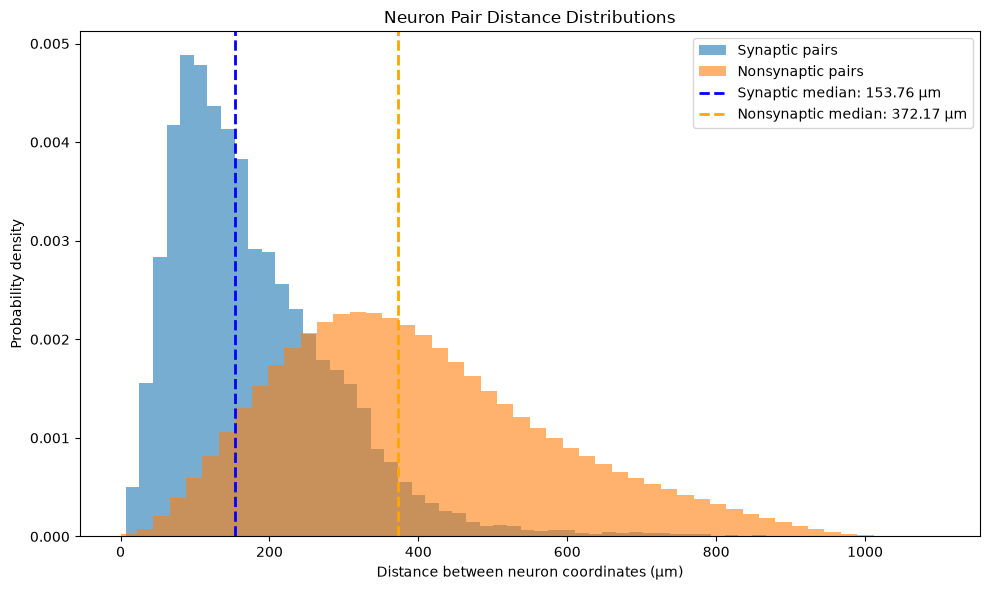

syn_median=     153.76 μm
nonsyn_median=  372.17 μm


In [190]:
import numpy as np
import matplotlib.pyplot as plt

synaptic_distances_um = synaptic_distances / 1000
nonsynaptic_distances_um = nonsynaptic_distances / 1000

synaptic_median = np.median(synaptic_distances_um)
nonsynaptic_median = np.median(nonsynaptic_distances_um)

plt.figure(figsize=(10, 6))

plt.hist(
  synaptic_distances_um,
  bins=50,
  alpha=0.6,
  density=True,
  label="Synaptic pairs",
)

plt.hist(
  nonsynaptic_distances_um,
  bins=50,
  alpha=0.6,
  density=True,
  label="Nonsynaptic pairs",
)

plt.axvline(
  synaptic_median,
  color="blue",
  linestyle="--",
  linewidth=2,
  label=f"Synaptic median: {synaptic_median:.2f} μm",
)

plt.axvline(
  nonsynaptic_median,
  color="orange",
  linestyle="--",
  linewidth=2,
  label=f"Nonsynaptic median: {nonsynaptic_median:.2f} μm",
)

plt.xlabel("Distance between neuron coordinates (μm)")
plt.ylabel("Probability density")
plt.title("Neuron Pair Distance Distributions")
plt.legend()
plt.tight_layout()
plt.show()

print(f"syn_median=     {synaptic_median:.2f} μm")
print(f"nonsyn_median=  {nonsynaptic_median:.2f} μm")


Find the best distance that maximizes both left area for synaptic and right area for nonsynaptic, normalized.

In [191]:
values = np.sort(np.unique(np.concatenate([synaptic_distances, nonsynaptic_distances])))
thresholds = (values[:-1] + values[1:]) / 2

syn_left = np.searchsorted(np.sort(synaptic_distances), thresholds, side="right") / len(synaptic_distances)
nonsyn_right = (len(nonsynaptic_distances) - np.searchsorted(np.sort(nonsynaptic_distances), thresholds, side="right")) / len(nonsynaptic_distances)

score = (syn_left + nonsyn_right) / 2

best_idx = np.argmax(score)
best_distance = thresholds[best_idx]

print(f"d_thresh=  {best_distance:.2f}")
print(f"syn_A=     {syn_left[best_idx]:.3%}")
print(f"nonsyn_A=  {nonsyn_right[best_idx]:.3%}")
print(f"accuracy=  {score[best_idx]:.3%}")

d_thresh=  245598.61
syn_A=     76.580%
nonsyn_A=  78.046%
accuracy=  77.313%


Evaulate this against every neuron pair to see true accuracy.

Positive pairs: 17,825
Negative pairs available: 8,982,175


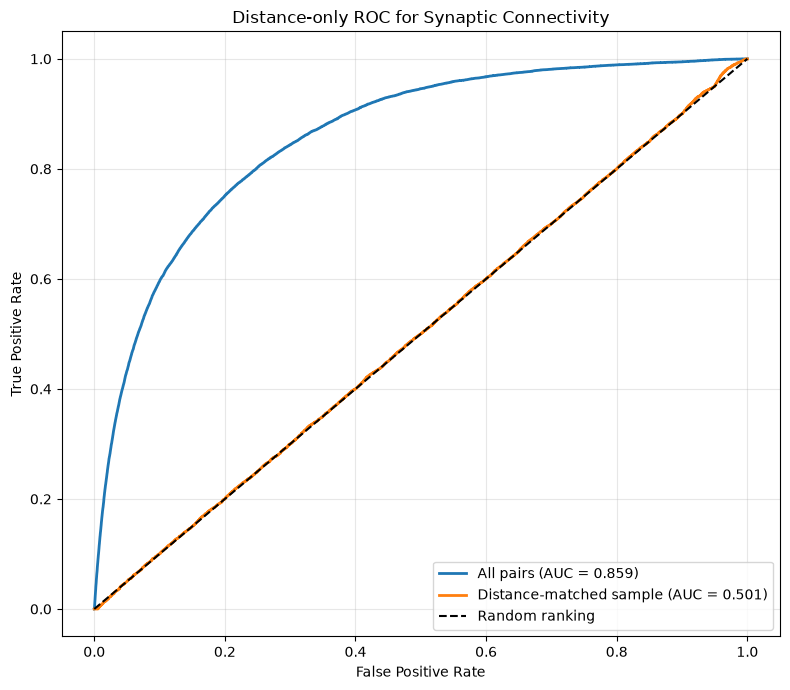

All-pairs ROC-AUC:       0.8591
Distance-matched AUC:    0.5013
Matched positives:       17,825
Matched negatives:       17,825


In [197]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from sklearn.metrics import (
  roc_curve,
  roc_auc_score,
)

distance_matrix = cdist(pre_xyz, post_xyz)

pre_idx = {nid: i for i, nid in enumerate(pre_ids)}
post_idx = {nid: i for i, nid in enumerate(post_ids)}

pairs = synapses_df[
    ["pre_pt_root_id", "post_pt_root_id"]
].drop_duplicates()

y_true_matrix = np.zeros(distance_matrix.shape, dtype=np.uint8)

for pre, post in pairs.itertuples(index=False, name=None):
    if pre in pre_idx and post in post_idx:
        y_true_matrix[pre_idx[pre], post_idx[post]] = 1

positive_idx = np.argwhere(y_true_matrix == 1)
negative_idx = np.argwhere(y_true_matrix == 0)

positive_distances = distance_matrix[
  positive_idx[:, 0], positive_idx[:, 1]
]

negative_distances = distance_matrix[
  negative_idx[:, 0], negative_idx[:, 1]
]

print(f"Positive pairs: {len(positive_distances):,}")
print(f"Negative pairs available: {len(negative_distances):,}")

rng = np.random.default_rng(42)

n_bins = 20
bin_edges = np.unique(
  np.quantile(
    positive_distances,
    np.linspace(0, 1, n_bins + 1),
  ),
)

if len(bin_edges) < 2:
  raise ValueError("Positive distances have insufficient variation for distance-bin matching.")

pos_bins = np.digitize(
  positive_distances, bin_edges[1:-1]
)
neg_bins = np.digitize(
  negative_distances, bin_edges[1:-1]
)

sampled_negative_parts = []

for b in np.unique(pos_bins):
  n_pos_bin = np.sum(pos_bins == b)
  candidates = np.flatnonzero(neg_bins == b)

  if n_pos_bin == 0 or len(candidates) == 0:
    continue

  n_sample = min(n_pos_bin, len(candidates))
  chosen = rng.choice(candidates, size=n_sample, replace=False)

  sampled_negative_parts.append(negative_distances[chosen])

if not sampled_negative_parts:
  raise ValueError("No negative pairs could be matched to positive distances.")

sampled_negative_distances = np.concatenate(
  sampled_negative_parts
)

# Use only positive pairs whose distance bins have negatives.
matched_positive_distances = np.concatenate([
  positive_distances[pos_bins == b]
  for b in np.unique(pos_bins)
  if np.sum(neg_bins == b) > 0
])


y_true_matched = np.concatenate([
  np.ones(len(matched_positive_distances), dtype=np.uint8),
  np.zeros(len(sampled_negative_distances), dtype=np.uint8),
])

y_score_matched = -np.concatenate([
  matched_positive_distances,
  sampled_negative_distances,
])

fpr_matched, tpr_matched, _ = roc_curve(
  y_true_matched, y_score_matched
)
auc_matched = roc_auc_score(
  y_true_matched, y_score_matched
)

y_true_all = y_true_matrix.ravel()
y_score_all = -distance_matrix.ravel()

fpr_all, tpr_all, _ = roc_curve(y_true_all, y_score_all)
auc_all = roc_auc_score(y_true_all, y_score_all)

plt.figure(figsize=(8, 7))

plt.plot(
  fpr_all, tpr_all,
  label=f"All pairs (AUC = {auc_all:.3f})",
  linewidth=2
)

plt.plot(
  fpr_matched, tpr_matched,
  label=f"Distance-matched sample (AUC = {auc_matched:.3f})",
  linewidth=2
)

plt.plot(
  [0, 1], [0, 1],
  "k--", label="Random ranking"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Distance-only ROC for Synaptic Connectivity")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"All-pairs ROC-AUC:       {auc_all:.4f}")
print(f"Distance-matched AUC:    {auc_matched:.4f}")
print(f"Matched positives:       {len(matched_positive_distances):,}")
print(f"Matched negatives:       {len(sampled_negative_distances):,}")
